Dataset Shape: (4998, 141)
Epoch 1/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 8s 462ms/step - loss: 0.0214 - val_loss: 0.0159
Epoch 2/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 80ms/step - loss: 0.0135 - val_loss: 0.0111
Epoch 3/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 119ms/step - loss: 0.0103 - val_loss: 0.0096
Epoch 4/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 75ms/step - loss: 0.0091 - val_loss: 0.0085
Epoch 5/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 66ms/step - loss: 0.0080 - val_loss: 0.0075
Epoch 6/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 89ms/step - loss: 0.0071 - val_loss: 0.0067
Epoch 7/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 62ms/step - loss: 0.0064 - val_loss: 0.0062
Epoch 8/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 76ms/step - loss: 0.0059 - val_loss: 0.0055
Epoch 9/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 62ms/step - loss: 0.0052 - val_loss: 0.0048
Epoch 10/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 62ms/step - loss: 0.0045 - val_loss: 0.0041
Epoch 11/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 60ms/step - loss: 0.0039 - val_loss: 0.0037
Epoch 12/20
10/10 ━━━━━━━━━━━━━━━━

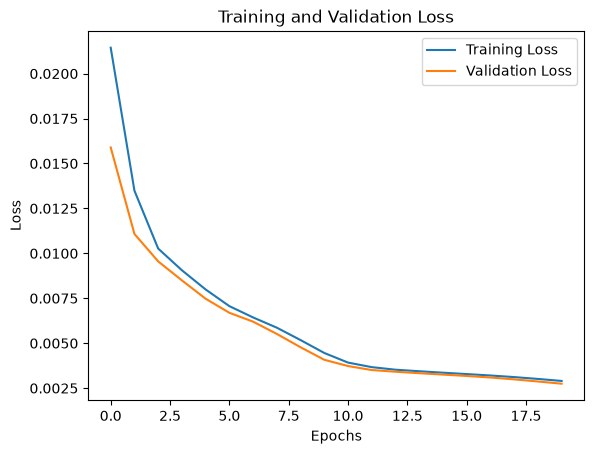

73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step
Threshold: 0.0073189083937149
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
Actual Labels: [0. 0. 1. 1. 1. 1. 0. 0. 0. 1.]
Predicted Labels: [0 0 1 1 0 1 0 0 0 1]
Accuracy: 97.1 %


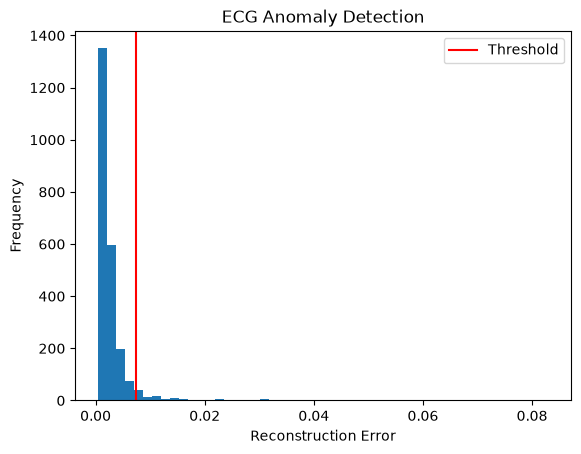

In [ ]:
# ECG Anomaly Detection using Autoencoder

# 1. Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score

from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense


# 2. Load ECG dataset
url = "https://storage.googleapis.com/download.tensorflow.org/data/ecg.csv"

data = pd.read_csv(url, header=None)

print("Dataset Shape:", data.shape)


# 3. Separate features and labels
X = data.iloc[:, :-1].values
y = data.iloc[:, -1].values


# 4. Split dataset
x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)


# 5. Select normal ECG data
x_train_normal = x_train[y_train == 1]
x_test_normal = x_test[y_test == 1]


# 6. Normalize data
scaler = MinMaxScaler()

x_train_normal = scaler.fit_transform(x_train_normal)
x_test_normal = scaler.transform(x_test_normal)
x_test = scaler.transform(x_test)


# 7. Build Autoencoder
input_layer = Input(shape=(140,))

encoded = Dense(128, activation='relu')(input_layer)
encoded = Dense(64, activation='relu')(encoded)
encoded = Dense(32, activation='relu')(encoded)

decoded = Dense(64, activation='relu')(encoded)
decoded = Dense(128, activation='relu')(decoded)
decoded = Dense(140, activation='sigmoid')(decoded)

autoencoder = Model(input_layer, decoded)


# 8. Compile model
autoencoder.compile(
    optimizer='adam',
    loss='mse'
)


# 9. Train model
history = autoencoder.fit(
    x_train_normal,
    x_train_normal,
    epochs=20,
    batch_size=256,
    validation_data=(x_test_normal, x_test_normal),
    shuffle=True
)


# 10. Plot training loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.show()


# 11. Calculate reconstruction error
train_pred = autoencoder.predict(x_train_normal)

train_error = np.mean(np.square(x_train_normal - train_pred), axis=1)

threshold = np.mean(train_error) + np.std(train_error)

print("Threshold:", threshold)


# 12. Detect anomalies
test_pred = autoencoder.predict(x_test)

test_error = np.mean(np.square(x_test - test_pred), axis=1)

# Normal = 1, Abnormal = 0
y_pred = np.where(test_error <= threshold, 1, 0)


# 13. Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Actual Labels:", y_test[:10])
print("Predicted Labels:", y_pred[:10])
print("Accuracy:", accuracy * 100, "%")


# 14. Plot reconstruction error
plt.hist(train_error, bins=50)
plt.axvline(threshold, color='red', label='Threshold')
plt.xlabel('Reconstruction Error')
plt.ylabel('Frequency')
plt.title('ECG Anomaly Detection')
plt.legend()
plt.show()


# 15. Display ECG signal
plt.plot(x_test[0])
plt.title('ECG Signal')
plt.xlabel('Time')
plt.ylabel('Amplitude')
plt.show()

# If sir gives dataframe = pd.read_csv('/content/ecg.csv', header=None)